# 16 · GCN on the patient-similarity networks

Notebook 14 averaged each stay's neighbours (GraphSAGE); notebook 15 *learned* a weight per link (GAT). **GCN** (`torch_geometric.nn.models.GCN`) uses a **fixed rule**: every stay is also linked to itself, and each link between *i* and *j* is scaled by 1 / √(deg *i* × deg *j*). Nothing about the weighting is learned, and stays with many links are damped: each of their links counts for less, and a link *to* a heavily linked stay counts for less too.

**Same protocol as notebooks 13, 14 and 15**, so every number can sit next to a linear, GraphSAGE or GAT one: the same patient-grouped 60/20/20 splits (same split seeds), columns standardised with the training stays only, settings and stopping epoch chosen on the validation stays, test stays scored once, repeated over `SEEDS` and reported as mean and spread.

**Four models:**

| model | what it is |
|---|---|
| `gcn` | GCN on the saved network, links present / absent |
| `gcn_w` | the same, with each link weighted by the **stored edge weight**. `gcn_w − gcn` is what the weights add |
| `mlp` | the *same* architecture and training with **every link removed** (each stay then keeps only its own features). `gcn − mlp` on identical splits is what the network adds |
| `gcn_nosame` | GCN with the links between two stays of the **same patient** removed (about a third of links) |

**Things to know before reading the numbers**

- Full-batch and **transductive**, exactly as in notebooks 14 and 15: the whole network is visible, only the *training* stays' outcomes are used, and a patient's stays always sit in one split.
- **Unlike GraphSAGE and GAT, GCN can use edge weights.** Only `gcn_w` does; the other three ignore them. The notebook looks at what the stored weights are before running anything.
- GCN has **no learned attention**, so there is no attention section here.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from ehrgraph.eval.aggregate import write_aggregate  # noqa: F401
from ehrgraph.gnn import gcn as G
from ehrgraph.gnn.linear_regressor import YEAR_BANDS
from ehrgraph.gnn.node_features import FEATURE_SETS, LEAKABLE_BLOCKS
from ehrgraph.project import setup
from ehrgraph.viz import network_figures as nf

p = setup()
nf.apply_style()

TASKS = {"guo_los": "long stay", "new_hypertension": "new high blood pressure"}
NAME = {"safe": "honest", "leaky": "cheating", "null": "random"}
SEEDS = range(5)               # keep equal to notebooks 14 and 15 so the models are paired on the same splits
CONFIGS = G.CONFIGS            # small grid, chosen on the validation stays for every split seed
print("device:", G.pick_device(), "| configs:", len(CONFIGS), "| seeds:", len(SEEDS))

/home/ianstedham/network-analysis-ml/trimmed-dataset/ehrshot-patient-graphs/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/ianstedham/network-analysis-ml/trimmed-dataset/ehrshot-patient-graphs/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


data folder: /home/ianstedham/network-analysis-ml/trimmed-dataset/ehrshot-patient-graphs/data/omop
results go to: /home/ianstedham/network-analysis-ml/trimmed-dataset/ehrshot-patient-graphs/results/aggregate
device: cpu | configs: 2 | seeds: 5


## Load the inputs from notebook 12

The same file and alignment checks as notebooks 13 to 15.

In [2]:
datasets, years = {}, {}
for task in TASKS:
    datasets[task] = torch.load(p.results / f"gnn_inputs_{task}.pt", weights_only=False)

    lab = p.labels(task)
    lab = lab[lab["patient_id"].isin(set(p.diagnoses))].reset_index(drop=True)
    d0 = next(iter(datasets[task].values()))
    assert (lab["value"].astype(int).to_numpy() == d0.y.numpy()).all(), "labels are not aligned with the saved stays"
    assert (pd.factorize(lab["patient_id"])[0] == d0.patient_idx.numpy()).all(), "patients are not aligned"
    years[task] = pd.to_datetime(lab["prediction_time"]).dt.year.to_numpy()
    print(f"{TASKS[task]}: {d0.num_nodes:,} stays, {d0.y.float().mean():.1%} positive, "
          f"{d0.edge_index.shape[1] // 2:,} links, {d0.edge_attr.float().mean():.1%} same-patient, "
          f"{len(datasets[task])} saved combinations")

long stay: 6,998 stays, 25.4% positive, 18,581 links, 37.8% same-patient, 16 saved combinations
new high blood pressure: 3,511 stays, 12.8% positive, 9,787 links, 29.4% same-patient, 16 saved combinations


## What are the stored edge weights?

`gcn_w` is only meaningful if the weights vary. For each saved network this prints how many distinct weights there are, their range, and whether **same-patient links** carry systematically different weights from links between different patients (if they do, `gcn_w` leans on them more or less than `gcn` does).

In [3]:
rows = []
for t in TASKS:
    for key, d in datasets[t].items():
        if key[2] != "dx" or key[1] != "safe":
            continue
        w = getattr(d, "edge_weight", None)
        if w is None:
            rows.append({"question": TASKS[t], "network": NAME[key[0]], "varies": False, "note": "no edge_weight stored"})
            continue
        w = w.float().numpy(); same = d.edge_attr.reshape(len(w), -1)[:, 0].numpy() > 0.5
        rows.append({"question": TASKS[t], "network": NAME[key[0]], "varies": G.has_weights(d), "distinct": len(np.unique(w.round(6))),
                     "min": w.min(), "median": np.median(w), "max": w.max(),
                     "mean, same-patient links": w[same].mean() if same.any() else np.nan,
                     "mean, other links": w[~same].mean() if (~same).any() else np.nan})
display(pd.DataFrame(rows).set_index(["question", "network"]).round(3))

varies  distinct    min  median  max  \
question                network                                          
long stay               honest      True     17111  0.128   0.403  1.0   
                        cheating    True      5321  0.110   0.363  1.0   
                        random      True     17111  0.128   0.403  1.0   
new high blood pressure honest      True      8690  0.119   0.361  1.0   
                        cheating    True      3604  0.085   0.302  1.0   
                        random      True      8690  0.119   0.361  1.0   

                                  mean, same-patient links  mean, other links  
question                network                                                
long stay               honest                       0.755              0.345  
                        cheating                     1.000              0.295  
                        random                       0.541              0.500  
new high blood pressure honest                       0.788              0.332  
                        cheating                     1.000              0.280  
                        random                       0.413              0.467

## Which feature sets and runs

The same choices as notebooks 14 and 15: the **diagnosis features** (`dx`) and the **CLMBR** vector when notebook 12 built it; the network-derived feature sets (`n2v`, `structure`) are left out because they would feed the same network in twice.

- `gcn` runs on every saved network (honest, cheating, random) × every feature source (honest or cheating diagnoses).
- `mlp` has no links, so it needs one run per feature source.
- `gcn_nosame` runs on the honest and cheating networks with honest diagnoses.
- `gcn_w` runs on those same two networks, and only where the weights vary (see above).

If CLMBR is present, every run for that question is restricted to the stays that **have** a CLMBR vector, so all models are scored on the same stays.

In [4]:
GNN_FEATURES = [fs for fs in ("dx", "clmbr") if any(k[2] == fs for ds in datasets.values() for k in ds)]

SUBSET = {t: None for t in TASKS}
for t in TASKS:
    d = next((d for k, d in datasets[t].items() if k[2] == "clmbr"), None)
    if d is not None:
        names = list(d.feature_names)
        vec = [i for i, n in enumerate(names) if n != "has_clmbr"]
        has = np.abs(d.x[:, vec].numpy()).sum(1) > 0               # a stay with no CLMBR vector is all zeros
        if not has.all():
            SUBSET[t] = has
        print(f"{TASKS[t]}: CLMBR vector for {has.mean():.1%} of stays" + (" -> restricting every run to them" if SUBSET[t] is not None else ""))

NEEDS_DX = lambda fs: any(b in LEAKABLE_BLOCKS for b in FEATURE_SETS[fs])

def pretty(model, key):
    g, s, fs = key
    parts = [model, fs]
    if model != "mlp":
        parts.append(f"net: {NAME[g]}")
    if NEEDS_DX(fs):
        parts.append(f"feat: {NAME[s]}")
    return " | ".join(parts)

runs = {}
for t, ds in datasets.items():
    r = []
    for fs in GNN_FEATURES:
        ks = [k for k in ds if k[2] == fs and (NEEDS_DX(fs) or k[1] == "safe")]       # the diagnosis source is irrelevant to CLMBR: run it once
        r += [("gcn", k) for k in ks]
        r += [("mlp", k) for k in ks if k[0] == "safe"]
        r += [("gcn_nosame", k) for k in ks if k[0] in ("safe", "leaky") and k[1] == "safe"]
        r += [("gcn_w", k) for k in ks if k[0] in ("safe", "leaky") and k[1] == "safe" and G.has_weights(ds[k])]
    runs[t] = r
    print(TASKS[t], len(r), "runs x", len(SEEDS), "seeds" + ("" if any(m == "gcn_w" for m, _ in r) else "  (no varying edge weights: gcn_w skipped)"))

long stay 11 runs x 5 seeds
new high blood pressure 11 runs x 5 seeds


## Run

A quick timing check first: one run, one seed. Multiply by the number of runs and seeds above to estimate the full cost; lower `SEEDS` or `CONFIGS` if it is too long.

In [5]:
import time
t1 = next(iter(TASKS))
t0 = time.time()
m0, k0 = runs[t1][0]
_ = G.evaluate_data(datasets[t1][k0], m0, 0, CONFIGS, years[t1], SUBSET[t1])
one = time.time() - t0
total = sum(len(r) for r in runs.values()) * len(SEEDS) * one
print(f"one run: {one:.1f}s -> about {total / 60:.0f} min for everything (rough: later runs differ in size)")

one run: 3.2s -> about 6 min for everything (rough: later runs differ in size)


In [6]:
res = {t: G.run_models(datasets[t], runs[t], SEEDS, year=years[t], subset=SUBSET[t], configs=CONFIGS, log=lambda s: None) for t in TASKS}

tables = {}
for t in TASKS:
    s = G.summarize(res[t])
    s.index = [pretty(m, (g, so, f)) for m, g, so, f in s.index]
    tables[t] = s
    print(f"{TASKS[t]} - test AUROC, mean and spread over {len(SEEDS)} splits")
    display(s[["mean", "sd", "test_ap", "epoch", "n_features"]].round(3))

long stay - test AUROC, mean and spread over 5 splits


,mean,sd,test_ap,epoch,n_features
gcn | dx | net: cheating | feat: cheating,0.746,0.013,0.485,67.0,65
gcn | dx | net: cheating | feat: honest,0.745,0.013,0.482,72.0,65
gcn | dx | net: random | feat: honest,0.683,0.004,0.436,48.4,65
gcn | dx | net: honest | feat: cheating,0.753,0.020,0.506,43.4,65
gcn | dx | net: honest | feat: honest,0.756,0.016,0.509,61.6,65
gcn_nosame | dx | net: cheating | feat: honest,0.754,0.020,0.499,61.0,65
gcn_nosame | dx | net: honest | feat: honest,0.766,0.018,0.521,63.2,65
gcn_w | dx | net: cheating | feat: honest,0.757,0.007,0.492,67.8,65
gcn_w | dx | net: honest | feat: honest,0.758,0.015,0.501,44.0,65
mlp | dx | feat: cheating,0.760,0.018,0.502,49.4,65


new high blood pressure - test AUROC, mean and spread over 5 splits


,mean,sd,test_ap,epoch,n_features
gcn | dx | net: cheating | feat: cheating,0.835,0.030,0.430,92.4,65
gcn | dx | net: cheating | feat: honest,0.716,0.055,0.317,47.6,65
gcn | dx | net: random | feat: honest,0.612,0.056,0.195,59.8,65
gcn | dx | net: honest | feat: cheating,0.801,0.026,0.381,42.8,65
gcn | dx | net: honest | feat: honest,0.655,0.045,0.251,29.2,65
gcn_nosame | dx | net: cheating | feat: honest,0.704,0.041,0.313,38.8,65
gcn_nosame | dx | net: honest | feat: honest,0.637,0.052,0.234,33.0,65
gcn_w | dx | net: cheating | feat: honest,0.709,0.050,0.316,39.8,65
gcn_w | dx | net: honest | feat: honest,0.669,0.037,0.265,29.4,65
mlp | dx | feat: cheating,0.901,0.019,0.568,76.2,65


`epoch` is the average stopping epoch (the epoch with the best validation AUROC). Values near the maximum of 200 mean training was still improving; values under about 10 mean the model peaked almost immediately and is probably just reading the features.

### Which settings were chosen

In [7]:
for t in TASKS:
    print(TASKS[t])
    display(res[t].groupby("model")[["hidden", "dropout", "weight_decay"]].agg(lambda s: s.value_counts().to_dict()))

long stay


,hidden,dropout,weight_decay
model,,,
gcn,{64: 25},"{0.5: 14, 0.2: 11}","{0.001: 14, 0.01: 11}"
gcn_nosame,{64: 10},"{0.5: 8, 0.2: 2}","{0.001: 8, 0.01: 2}"
gcn_w,{64: 10},"{0.5: 6, 0.2: 4}","{0.001: 6, 0.01: 4}"
mlp,{64: 10},"{0.2: 5, 0.5: 5}","{0.01: 5, 0.001: 5}"


new high blood pressure


,hidden,dropout,weight_decay
model,,,
gcn,{64: 25},"{0.5: 13, 0.2: 12}","{0.001: 13, 0.01: 12}"
gcn_nosame,{64: 10},"{0.5: 9, 0.2: 1}","{0.001: 9, 0.01: 1}"
gcn_w,{64: 10},"{0.5: 8, 0.2: 2}","{0.001: 8, 0.01: 2}"
mlp,{64: 10},"{0.5: 5, 0.2: 5}","{0.001: 5, 0.01: 5}"


## The questions we care about

Each row is a **paired difference** in test AUROC (A minus B) on identical splits, so split luck cancels. `fraction_a_higher` is the share of splits where A won. A difference smaller than its `sd` is not a finding.

Read the first block for **what the network adds**, the second for **whether cheating changes anything**.

In [8]:
H = ("safe", "safe", "dx")           # honest network, honest diagnoses
PAIRS = [
    # --- what does the network add? (same features, links on vs off)
    ("network adds, honest net:  gcn - mlp",                     ("gcn", *H),                        ("mlp", *H)),
    ("network adds, cheating net:  gcn - mlp",                   ("gcn", "leaky", "safe", "dx"),     ("mlp", *H)),
    ("network adds, random net:  gcn - mlp",                     ("gcn", "null", "safe", "dx"),      ("mlp", *H)),
    ("real vs random network (gcn)",                             ("gcn", *H),                        ("gcn", "null", "safe", "dx")),
    ("without same-patient links:  gcn_nosame - mlp",            ("gcn_nosame", *H),                 ("mlp", *H)),
    ("same-patient links matter?  gcn - gcn_nosame",             ("gcn", *H),                        ("gcn_nosame", *H)),
    # --- do the edge weights help?
    ("edge weights add, honest net:  gcn_w - gcn",               ("gcn_w", *H),                      ("gcn", *H)),
    ("edge weights add, cheating net:  gcn_w - gcn",             ("gcn_w", "leaky", "safe", "dx"),   ("gcn", "leaky", "safe", "dx")),
    # --- does cheating change anything?
    ("cheating network vs honest (gcn, honest dx)",              ("gcn", "leaky", "safe", "dx"),     ("gcn", *H)),
    ("cheating diagnoses vs honest (gcn, honest net)",           ("gcn", "safe", "leaky", "dx"),     ("gcn", *H)),
    ("both cheat vs both honest (gcn)",                          ("gcn", "leaky", "leaky", "dx"),    ("gcn", *H)),
    ("cheating diagnoses vs honest (mlp, no network)",           ("mlp", "safe", "leaky", "dx"),     ("mlp", *H)),
    # --- CLMBR (only if notebook 12 built it)
    ("CLMBR vs diagnoses (gcn, honest net)",                     ("gcn", "safe", "safe", "clmbr"),   ("gcn", *H)),
    ("network adds to CLMBR:  gcn - mlp",                        ("gcn", "safe", "safe", "clmbr"),   ("mlp", "safe", "safe", "clmbr")),
]
out = []
for t in TASKS:
    have = {tuple(r) for r in res[t][G.KEY].drop_duplicates().to_numpy()}
    for name, a, b in PAIRS:
        if a in have and b in have:
            out.append({"question": TASKS[t], "A minus B": name, **G.paired(res[t], a, b)})
if out:
    display(pd.DataFrame(out).set_index(["question", "A minus B"]).round(3))
else:
    print("none of these comparisons were run")

mean_diff  \
question                A minus B                                                   
long stay               network adds, honest net:  gcn - mlp               -0.015   
                        network adds, cheating net:  gcn - mlp             -0.026   
                        network adds, random net:  gcn - mlp               -0.088   
                        real vs random network (gcn)                        0.073   
                        without same-patient links:  gcn_nosame - mlp      -0.005   
                        same-patient links matter?  gcn - gcn_nosame       -0.009   
                        edge weights add, honest net:  gcn_w - gcn          0.002   
                        edge weights add, cheating net:  gcn_w - gcn        0.012   
                        cheating network vs honest (gcn, honest dx)        -0.011   
                        cheating diagnoses vs honest (gcn, honest net)     -0.004   
                        both cheat vs both honest (gcn)                    -0.010   
                        cheating diagnoses vs honest (mlp, no network)     -0.011   
new high blood pressure network adds, honest net:  gcn - mlp                0.006   
                        network adds, cheating net:  gcn - mlp              0.067   
                        network adds, random net:  gcn - mlp               -0.037   
                        real vs random network (gcn)                        0.043   
                        without same-patient links:  gcn_nosame - mlp      -0.013   
                        same-patient links matter?  gcn - gcn_nosame        0.019   
                        edge weights add, honest net:  gcn_w - gcn          0.014   
                        edge weights add, cheating net:  gcn_w - gcn       -0.007   
                        cheating network vs honest (gcn, honest dx)         0.061   
                        cheating diagnoses vs honest (gcn, honest net)      0.146   
                        both cheat vs both honest (gcn)                     0.180   
                        cheating diagnoses vs honest (mlp, no network)      0.252   

                                                                           sd  \
question                A minus B                                               
long stay               network adds, honest net:  gcn - mlp            0.014   
                        network adds, cheating net:  gcn - mlp          0.009   
                        network adds, random net:  gcn - mlp            0.017   
                        real vs random network (gcn)                    0.013   
                        without same-patient links:  gcn_nosame - mlp   0.008   
                        same-patient links matter?  gcn - gcn_nosame    0.011   
                        edge weights add, honest net:  gcn_w - gcn      0.007   
                        edge weights add, cheating net:  gcn_w - gcn    0.008   
                        cheating network vs honest (gcn, honest dx)     0.015   
                        cheating diagnoses vs honest (gcn, honest net)  0.016   
                        both cheat vs both honest (gcn)                 0.018   
                        cheating diagnoses vs honest (mlp, no network)  0.016   
new high blood pressure network adds, honest net:  gcn - mlp            0.056   
                        network adds, cheating net:  gcn - mlp          0.050   
                        network adds, random net:  gcn - mlp            0.062   
                        real vs random network (gcn)                    0.049   
                        without same-patient links:  gcn_nosame - mlp   0.056   
                        same-patient links matter?  gcn - gcn_nosame    0.008   
                        edge weights add, honest net:  gcn_w - gcn      0.009   
                        edge weights add, cheating net:  gcn_w - gcn    0.015   
                        cheating network vs honest (gcn, honest dx)     0.015  

## Against the linear baseline (13), GraphSAGE (14) and GAT (15)

GCN minus the other model on the **same features and the same splits**, for the seeds both notebooks ran, and not for questions restricted to a CLMBR subset (their splits differ). `gcn` is compared with `sage` and `gat`, `gcn_nosame` with `sage_nosame` and `gat_nosame`, and `mlp` with `mlp` (a check that the "no links" models of the different architectures agree). `gcn_w` has no counterpart in the other notebooks and is left out. A GCN that does not beat the linear row, or the other networks, is not earning its extra complexity.

In [9]:
def vs_other(csv, label, model_map=None, require_graph_safe=False):
    f = p.results / csv
    if not f.exists():
        print(f"{label}: run the earlier notebook first ({csv} not found)")
        return
    other = pd.read_csv(f)
    rows = []
    for t in TASKS:
        if SUBSET[t] is not None:
            continue
        O = other[other["question"] == TASKS[t]]
        for m, g, so, fs in res[t][G.KEY].drop_duplicates().itertuples(index=False):
            om = (model_map or {}).get(m)
            if (model_map is not None and om is None) or (model_map is None and m == "gcn_w"):
                continue
            sel = (O.source == so) & (O.feature_set == fs)
            sel &= (O.graph == "safe") if require_graph_safe else (O.graph == g)
            if model_map is not None:
                sel &= O.model == om
            orow = O[sel].set_index("seed")["test_auc"]
            srow = res[t][(res[t].model == m) & (res[t].graph == g) & (res[t].source == so) & (res[t].feature_set == fs)].set_index("seed")["test_auc"]
            d = (srow - orow).dropna()
            if len(d):
                rows.append({"question": TASKS[t], "model": pretty(m, (g, so, fs)), "mean_diff": d.mean(), "sd": d.std(),
                             "n_seeds": len(d), "fraction_higher": float((d > 0).mean())})
    print(label)
    display(pd.DataFrame(rows).set_index(["question", "model"]).round(3) if rows else "nothing to compare (CLMBR subsets or no shared seeds)")

vs_other("linear_baselines.csv", "GCN minus the linear model (notebook 13, same diagnosis features)", require_graph_safe=True)
vs_other("graphsage_results.csv", "GCN minus GraphSAGE (notebook 14)", model_map={"gcn": "sage", "mlp": "mlp", "gcn_nosame": "sage_nosame"})
vs_other("gat_results.csv", "GCN minus GAT (notebook 15)", model_map={"gcn": "gat", "mlp": "mlp", "gcn_nosame": "gat_nosame"})

GCN minus the linear model (notebook 13, same diagnosis features)


mean_diff  \
question                model                                                       
long stay               gcn | dx | net: honest | feat: honest               0.009   
                        gcn | dx | net: honest | feat: cheating            -0.002   
                        gcn | dx | net: cheating | feat: honest            -0.002   
                        gcn | dx | net: cheating | feat: cheating          -0.008   
                        gcn | dx | net: random | feat: honest              -0.064   
                        mlp | dx | feat: honest                             0.024   
                        mlp | dx | feat: cheating                           0.006   
                        gcn_nosame | dx | net: honest | feat: honest        0.019   
                        gcn_nosame | dx | net: cheating | feat: honest      0.007   
new high blood pressure gcn | dx | net: honest | feat: honest               0.061   
                        gcn | dx | net: honest | feat: cheating            -0.050   
                        gcn | dx | net: cheating | feat: honest             0.122   
                        gcn | dx | net: cheating | feat: cheating          -0.016   
                        gcn | dx | net: random | feat: honest               0.018   
                        mlp | dx | feat: honest                             0.055   
                        mlp | dx | feat: cheating                           0.050   
                        gcn_nosame | dx | net: honest | feat: honest        0.042   
                        gcn_nosame | dx | net: cheating | feat: honest      0.110   

                                                                           sd  \
question                model                                                   
long stay               gcn | dx | net: honest | feat: honest           0.025   
                        gcn | dx | net: honest | feat: cheating         0.009   
                        gcn | dx | net: cheating | feat: honest         0.011   
                        gcn | dx | net: cheating | feat: cheating       0.015   
                        gcn | dx | net: random | feat: honest           0.020   
                        mlp | dx | feat: honest                         0.015   
                        mlp | dx | feat: cheating                       0.015   
                        gcn_nosame | dx | net: honest | feat: honest    0.022   
                        gcn_nosame | dx | net: cheating | feat: honest  0.008   
new high blood pressure gcn | dx | net: honest | feat: honest           0.041   
                        gcn | dx | net: honest | feat: cheating         0.027   
                        gcn | dx | net: cheating | feat: honest         0.050   
                        gcn | dx | net: cheating | feat: cheating       0.022   
                        gcn | dx | net: random | feat: honest           0.061   
                        mlp | dx | feat: honest                         0.054   
                        mlp | dx | feat: cheating                       0.016   
                        gcn_nosame | dx | net: honest | feat: honest    0.047   
                        gcn_nosame | dx | net: cheating | feat: honest  0.037   

                                                                        n_seeds  \
question                model                                                     
long stay               gcn | dx | net: honest | feat: honest                 5   
                        gcn | dx | net: honest | feat: cheating               5   
                        gcn | dx | net: cheating | feat: honest               5   
                        gcn | dx | net: cheating | feat: cheating             5   
                        gcn | dx | net: random | feat: honest                 5   
                        mlp | dx | feat: honest                               5   
                        mlp | dx | feat: cheating                             5   
   

GCN minus GraphSAGE (notebook 14)


mean_diff  \
question                model                                                       
long stay               gcn | dx | net: honest | feat: honest              -0.011   
                        gcn | dx | net: honest | feat: cheating             0.002   
                        gcn | dx | net: cheating | feat: honest            -0.014   
                        gcn | dx | net: cheating | feat: cheating          -0.005   
                        mlp | dx | feat: honest                            -0.005   
                        mlp | dx | feat: cheating                           0.001   
                        gcn_nosame | dx | net: honest | feat: honest        0.002   
                        gcn_nosame | dx | net: cheating | feat: honest     -0.010   
new high blood pressure gcn | dx | net: honest | feat: honest              -0.013   
                        gcn | dx | net: honest | feat: cheating            -0.080   
                        gcn | dx | net: cheating | feat: honest             0.035   
                        gcn | dx | net: cheating | feat: cheating          -0.044   
                        mlp | dx | feat: honest                            -0.024   
                        mlp | dx | feat: cheating                           0.006   
                        gcn_nosame | dx | net: honest | feat: honest       -0.022   
                        gcn_nosame | dx | net: cheating | feat: honest      0.019   

                                                                           sd  \
question                model                                                   
long stay               gcn | dx | net: honest | feat: honest           0.024   
                        gcn | dx | net: honest | feat: cheating         0.015   
                        gcn | dx | net: cheating | feat: honest         0.007   
                        gcn | dx | net: cheating | feat: cheating       0.015   
                        mlp | dx | feat: honest                         0.011   
                        mlp | dx | feat: cheating                       0.007   
                        gcn_nosame | dx | net: honest | feat: honest    0.013   
                        gcn_nosame | dx | net: cheating | feat: honest  0.010   
new high blood pressure gcn | dx | net: honest | feat: honest           0.044   
                        gcn | dx | net: honest | feat: cheating         0.012   
                        gcn | dx | net: cheating | feat: honest         0.032   
                        gcn | dx | net: cheating | feat: cheating       0.025   
                        mlp | dx | feat: honest                         0.035   
                        mlp | dx | feat: cheating                       0.005   
                        gcn_nosame | dx | net: honest | feat: honest    0.050   
                        gcn_nosame | dx | net: cheating | feat: honest  0.042   

                                                                        n_seeds  \
question                model                                                     
long stay               gcn | dx | net: honest | feat: honest                 5   
                        gcn | dx | net: honest | feat: cheating               5   
                        gcn | dx | net: cheating | feat: honest               5   
                        gcn | dx | net: cheating | feat: cheating             5   
                        mlp | dx | feat: honest                               5   
                        mlp | dx | feat: cheating                             5   
                        gcn_nosame | dx | net: honest | feat: honest          5   
                        gcn_nosame | dx | net: cheating | feat: honest        5   
new high blood pressure gcn | dx | net: honest | feat: honest                 5   
                        gcn | dx | net: honest | feat: cheating               5   
                        gcn | dx | net: cheating | feat: honest               5   
   

GCN minus GAT (notebook 15)


mean_diff  \
question                model                                                       
long stay               gcn | dx | net: honest | feat: honest              -0.008   
                        gcn | dx | net: honest | feat: cheating            -0.008   
                        gcn | dx | net: cheating | feat: honest            -0.013   
                        gcn | dx | net: cheating | feat: cheating          -0.008   
                        mlp | dx | feat: honest                            -0.006   
                        mlp | dx | feat: cheating                          -0.008   
                        gcn_nosame | dx | net: honest | feat: honest       -0.006   
                        gcn_nosame | dx | net: cheating | feat: honest     -0.016   
new high blood pressure gcn | dx | net: honest | feat: honest              -0.017   
                        gcn | dx | net: honest | feat: cheating             0.007   
                        gcn | dx | net: cheating | feat: honest            -0.007   
                        gcn | dx | net: cheating | feat: cheating          -0.002   
                        mlp | dx | feat: honest                            -0.042   
                        mlp | dx | feat: cheating                           0.007   
                        gcn_nosame | dx | net: honest | feat: honest       -0.034   
                        gcn_nosame | dx | net: cheating | feat: honest     -0.021   

                                                                           sd  \
question                model                                                   
long stay               gcn | dx | net: honest | feat: honest           0.020   
                        gcn | dx | net: honest | feat: cheating         0.011   
                        gcn | dx | net: cheating | feat: honest         0.014   
                        gcn | dx | net: cheating | feat: cheating       0.013   
                        mlp | dx | feat: honest                         0.021   
                        mlp | dx | feat: cheating                       0.012   
                        gcn_nosame | dx | net: honest | feat: honest    0.018   
                        gcn_nosame | dx | net: cheating | feat: honest  0.016   
new high blood pressure gcn | dx | net: honest | feat: honest           0.032   
                        gcn | dx | net: honest | feat: cheating         0.015   
                        gcn | dx | net: cheating | feat: honest         0.022   
                        gcn | dx | net: cheating | feat: cheating       0.007   
                        mlp | dx | feat: honest                         0.033   
                        mlp | dx | feat: cheating                       0.009   
                        gcn_nosame | dx | net: honest | feat: honest    0.036   
                        gcn_nosame | dx | net: cheating | feat: honest  0.013   

                                                                        n_seeds  \
question                model                                                     
long stay               gcn | dx | net: honest | feat: honest                 5   
                        gcn | dx | net: honest | feat: cheating               5   
                        gcn | dx | net: cheating | feat: honest               5   
                        gcn | dx | net: cheating | feat: cheating             5   
                        mlp | dx | feat: honest                               5   
                        mlp | dx | feat: cheating                             5   
                        gcn_nosame | dx | net: honest | feat: honest          5   
                        gcn_nosame | dx | net: cheating | feat: honest        5   
new high blood pressure gcn | dx | net: honest | feat: honest                 5   
                        gcn | dx | net: honest | feat: cheating               5   
                        gcn | dx | net: cheating | feat: honest               5   
   

## Year-adjusted view

Test AUROC **within** calendar-year bands (2015 is the coding switch). A model that wins only by learning the calendar will not keep its score here. Bands with fewer than 10 positive or 10 negative test stays are left blank, so blood-pressure bands are noisy.

In [10]:
band_cols = [f"auc_{b}" for b in YEAR_BANDS]
for t in TASKS:
    df = res[t].copy()
    df["run"] = [pretty(m, (g, s, f)) for m, g, s, f in zip(df.model, df.graph, df.source, df.feature_set)]
    print(TASKS[t]); display(df.groupby("run")[["test_auc", *band_cols]].mean().round(3))

long stay


,test_auc,auc_2007-2014,auc_2015-2018,auc_2019-2023
run,,,,
gcn | dx | net: cheating | feat: cheating,0.746,0.708,0.775,0.776
gcn | dx | net: cheating | feat: honest,0.745,0.727,0.762,0.762
gcn | dx | net: honest | feat: cheating,0.753,0.714,0.775,0.788
gcn | dx | net: honest | feat: honest,0.756,0.721,0.777,0.789
gcn | dx | net: random | feat: honest,0.683,0.659,0.695,0.713
gcn_nosame | dx | net: cheating | feat: honest,0.754,0.737,0.765,0.769
gcn_nosame | dx | net: honest | feat: honest,0.766,0.738,0.783,0.794
gcn_w | dx | net: cheating | feat: honest,0.757,0.733,0.777,0.779
gcn_w | dx | net: honest | feat: honest,0.758,0.737,0.770,0.784


new high blood pressure


,test_auc,auc_2007-2014,auc_2015-2018,auc_2019-2023
run,,,,
gcn | dx | net: cheating | feat: cheating,0.835,0.795,0.831,0.841
gcn | dx | net: cheating | feat: honest,0.716,0.675,0.762,0.666
gcn | dx | net: honest | feat: cheating,0.801,0.748,0.820,0.819
gcn | dx | net: honest | feat: honest,0.655,0.601,0.734,0.611
gcn | dx | net: random | feat: honest,0.612,0.589,0.695,0.530
gcn_nosame | dx | net: cheating | feat: honest,0.704,0.677,0.748,0.637
gcn_nosame | dx | net: honest | feat: honest,0.637,0.586,0.712,0.573
gcn_w | dx | net: cheating | feat: honest,0.709,0.663,0.764,0.676
gcn_w | dx | net: honest | feat: honest,0.669,0.604,0.768,0.638


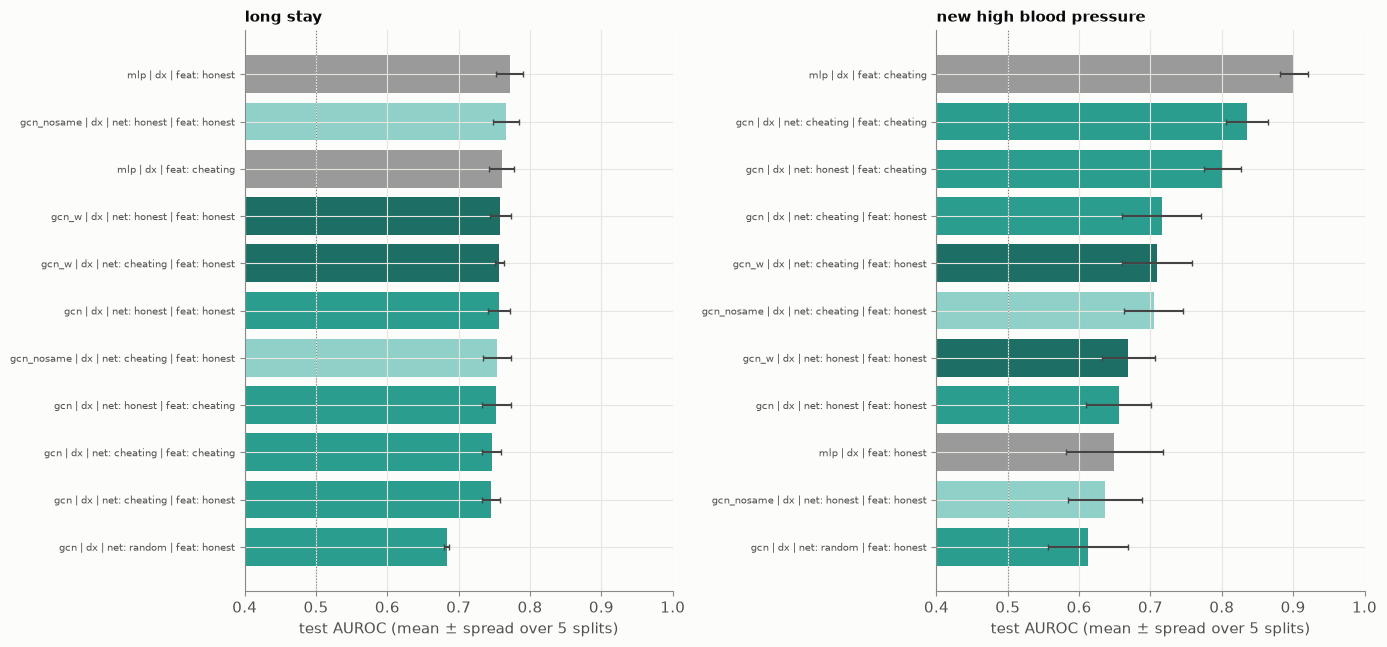

In [11]:
COLOR = {"gcn": "#2a9d8f", "gcn_w": "#1d6f65", "mlp": "#9a9a9a", "gcn_nosame": "#8fd0c8"}
fig, axes = plt.subplots(1, len(TASKS), figsize=(14, 6.6), sharex=False)
for ax, t in zip(np.atleast_1d(axes), TASKS):
    s = tables[t].sort_values("mean")
    ax.barh(s.index, s["mean"], xerr=s["sd"], color=[COLOR[i.split(" | ")[0]] for i in s.index], ecolor="#444", capsize=2)
    ax.axvline(0.5, color="grey", lw=0.8, ls=":"); ax.set_xlim(0.4, 1.0)
    ax.set_title(TASKS[t]); ax.set_xlabel(f"test AUROC (mean ± spread over {len(SEEDS)} splits)")
    ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
nf.save(fig, p.figures / "16_gcn.png")
plt.show()

In [12]:
# aggregate numbers only (no patient data)
pd.concat({TASKS[t]: res[t] for t in TASKS}, names=["question"]).reset_index(level=0) \
  .to_csv(p.results / "gcn_results.csv", index=False)

## What we learned

*(fill in after running)*

- **Does the network help at all?** `gcn − mlp` on the honest network, per question. If it is within its spread of zero, GCN is just reading each stay's own features, as the other two were.
- **Do the edge weights help?** `gcn_w − gcn`. A difference inside the spread means the similarity weights add nothing over present / absent links.
- **Is it the network, or just having a graph?** `gcn` on the real network vs the random one.
- **Same-patient links.** `gcn − gcn_nosame`.
- **Does cheating show up?** Cheating *diagnoses* should lift blood pressure (notebook 03) and not long stay (notebook 02). Does a cheating *network* change anything once the features are honest?
- **Against the other models.** Is any of GCN, GraphSAGE and GAT better than the others, and does any beat the linear model, once you compare against the `mlp` with no links?
- **Year.** Does any model's score survive within year bands?
- **CLMBR** (only if `CLMBR_PATH` was set in notebook 12).

## Read these results carefully

- **Transductive.** Test stays' features, and their links to training stays, take part in message passing. No test outcome is used, so this is not label leakage.
- **Fixed weighting.** GCN damps stays with many links. If the network matters mostly through a few well-connected stays, this can hide or exaggerate it relative to GraphSAGE's plain average.
- **Possible time leak in same-patient links.** A link to a patient's *later* stay brings in that stay's record. `gcn_nosame` shows how much the result depends on those links at all.
- **Calendar year.** Year alone scores about 0.64 on blood pressure; a model near that has learned little else.
- **Selection on validation.** Settings and stopping epoch come from the validation stays, so the validation score is slightly optimistic; the test score is untouched by that.
- **Small positive counts.** Blood pressure has about 90 positive test stays, so differences of a point or two are noise. Prefer the paired tables to eyeballing the bars.
- **Small search.** Two settings, 64 hidden, 2 layers.